In [2]:
from pathlib import Path
import random
import torch
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
out = Path("lab_outputs")
out.mkdir(exist_ok=True)
print("Device:", device)

Device: cpu


In [3]:
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import torch.nn.functional as F

train = datasets.MNIST("data", train=True, download=True, transform=transforms.ToTensor())
test = datasets.MNIST("data", train=False, download=True, transform=transforms.ToTensor())
loader = DataLoader(train, batch_size=128, shuffle=True)
test_loader = DataLoader(test, batch_size=1024, shuffle=False)

100%|██████████| 9.91M/9.91M [00:00<00:00, 131MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 12.1MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 56.7MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.00MB/s]


In [8]:
class VAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU())
        self.mean = nn.Linear(256, 2)
        self.logvar = nn.Linear(256, 2)
        self.decoder = nn.Sequential(nn.Linear(2, 256), nn.ReLU(), nn.Linear(256, 784), nn.Sigmoid())

    def encode(self, x):
        h = self.encoder(x)
        return self.mean(h), self.logvar(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
        return self.decoder(z), mu, logvar

vae = VAE().to(device)
optimizer = torch.optim.Adam(vae.parameters(), lr=0.001)

In [5]:
vae_history = []
for epoch in range(1, 6):
    vae.train()
    total_recon = 0.0
    total_kl = 0.0
    for x, _ in loader:
        x = x.to(device)
        generated, mu, logvar = vae(x)
        recon = F.binary_cross_entropy(generated, x.flatten(1), reduction="sum")
        kl = -0.5 * (1 + logvar - mu.square() - logvar.exp()).sum()
        loss = (recon + kl) / x.size(0)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_recon += recon.item()
        total_kl += kl.item()
    recon_avg = total_recon / len(train)
    kl_avg = total_kl / len(train)
    vae_history.append((recon_avg, kl_avg))
    print(f"Epoch {epoch}: Reconstruction={recon_avg:.2f}, KL={kl_avg:.2f}")
torch.save(vae.state_dict(), out / "vae_mnist.pt")

Epoch 1: Reconstruction=189.31, KL=6.57
Epoch 2: Reconstruction=165.50, KL=5.34
Epoch 3: Reconstruction=160.08, KL=5.41
Epoch 4: Reconstruction=157.20, KL=5.47
Epoch 5: Reconstruction=155.31, KL=5.51


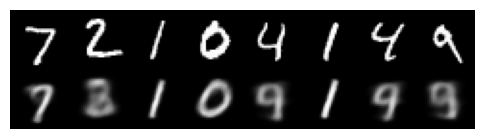

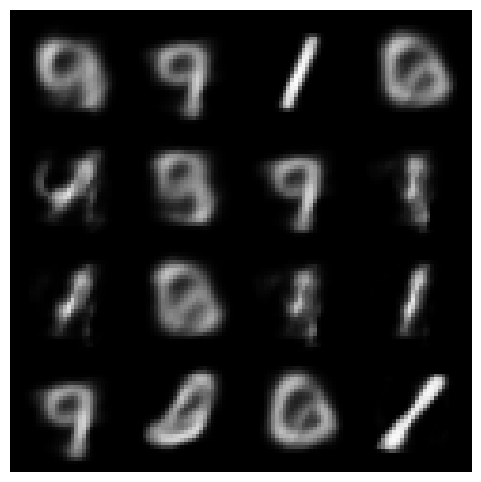

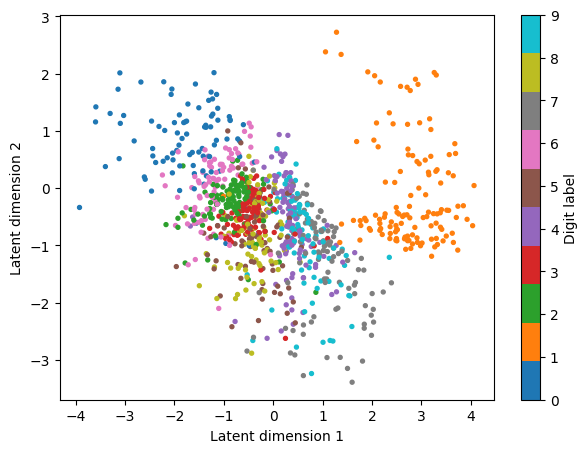

Saved: [PosixPath('lab_outputs/vae_latent.png'), PosixPath('lab_outputs/vae_reconstructed.png'), PosixPath('lab_outputs/vae_generated.png')]


In [6]:
def show_grid(images, filename, nrow=4):
    grid = make_grid(images.cpu(), nrow=nrow)
    plt.figure(figsize=(6, 6))
    plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray")
    plt.axis("off")
    plt.savefig(out / filename, bbox_inches="tight")
    plt.show()

vae.eval()
with torch.no_grad():
    x, y = next(iter(test_loader))
    mu, _ = vae.encode(x.to(device))
    recon = vae.decoder(mu[:8]).reshape(-1, 1, 28, 28).cpu()
    samples = vae.decoder(torch.randn(16, 2, device=device)).reshape(-1, 1, 28, 28).cpu()
    show_grid(torch.cat([x[:8], recon]), "vae_reconstructed.png", nrow=8)
    show_grid(samples, "vae_generated.png", nrow=4)
    coords = mu.cpu()
plt.figure(figsize=(7, 5))
plt.scatter(coords[:, 0], coords[:, 1], c=y, cmap="tab10", s=8)
plt.colorbar(ticks=range(10), label="Digit label")
plt.xlabel("Latent dimension 1")
plt.ylabel("Latent dimension 2")
plt.savefig(out / "vae_latent.png", bbox_inches="tight")
plt.show()
print("Saved:", list(out.glob("vae_*.png")))

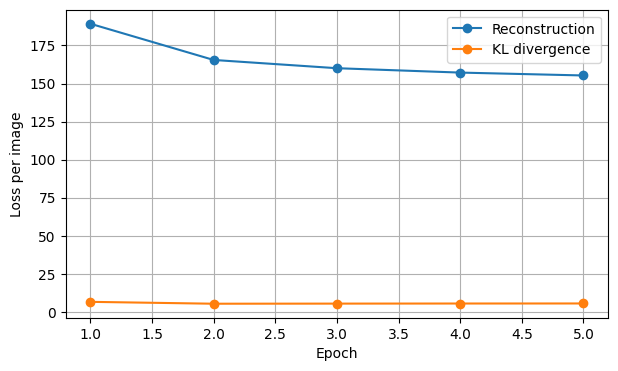

Epoch | Reconstruction loss | KL divergence
1 189.31 6.57
2 165.5 5.34
3 160.08 5.41
4 157.2 5.47
5 155.31 5.51


In [7]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, 6), [v[0] for v in vae_history], marker="o", label="Reconstruction")
plt.plot(range(1, 6), [v[1] for v in vae_history], marker="o", label="KL divergence")
plt.xlabel("Epoch")
plt.ylabel("Loss per image")
plt.legend()
plt.grid()
plt.show()
print("Epoch | Reconstruction loss | KL divergence")
for epoch, values in enumerate(vae_history, 1):
    print(epoch, round(values[0], 2), round(values[1], 2))